# 06 — Error analysis and interpretation

This notebook looks closely at the preferred model (gradient boosting, 400 rounds, on TF-IDF word features):
1. **Where it goes wrong**, using out-of-fold predictions on the training set: every training book is predicted by a model that never saw it (or its author), using the same 5 folds as before.
2. **Error slices with uncertainty**: performance per period and for books near a period boundary, with book counts and 95% confidence intervals.
3. **The 1850–1899 / 1900–1918 confusion**, the most common mistake.
4. **Final test-set performance with a confidence interval**, for the model card. No decisions are made from the test set here; the model was fixed in notebook 03.
5. **Calibration**: whether the predicted probabilities can be trusted.
6. **Interpretation**: one global explanation (permutation importance) and one local explanation (why one book was dated wrongly), with the limits of both methods.

## Setup

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay

from src import config

In [2]:
train = pd.read_csv(config.PROCESSED_DIR / "train.csv")
test = pd.read_csv(config.PROCESSED_DIR / "test.csv")
PERIODS = ["pre-1750", "1750-1799", "1800-1849", "1850-1899", "1900-1918"]
INDEX = {p: i for i, p in enumerate(PERIODS)}

cv = StratifiedGroupKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)

def tfidf():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", min_df=10)

def boosting_model():
    return make_pipeline(tfidf(), GradientBoostingClassifier(
        n_estimators=400, learning_rate=0.1, max_depth=3, max_features="sqrt", random_state=config.RANDOM_STATE))

print("Train:", train.shape, " Test:", test.shape)

Train: (288, 6)  Test: (71, 6)


## Out-of-fold predictions

`cross_val_predict` trains on 4 folds and predicts the 5th, for each fold in turn, so every training book gets exactly one prediction from a model that has not seen it. This gives 288 predictions to analyse instead of 71 test books, without touching the test set.

`error_size` is how many periods away the prediction is (1 = a neighbouring period).

In [3]:
train["pred"] = cross_val_predict(boosting_model(), train["excerpt"], train["period"],
                                  groups=train["group"], cv=cv)
train["error_size"] = (train["period"].map(INDEX) - train["pred"].map(INDEX)).abs()

errors = train[train["error_size"] > 0]
print(f"Out-of-fold macro-F1: {f1_score(train['period'], train['pred'], average='macro'):.3f}  "
      f"accuracy: {accuracy_score(train['period'], train['pred']):.3f}")
print(f"Errors: {len(errors)} of {len(train)};  in a neighbouring period: {(errors['error_size'] == 1).mean():.0%}")
errors["error_size"].value_counts().sort_index()

Out-of-fold macro-F1: 0.515  accuracy: 0.497
Errors: 145 of 288;  in a neighbouring period: 82%


error_size
1    119
2     20
3      4
4      2
Name: count, dtype: int64

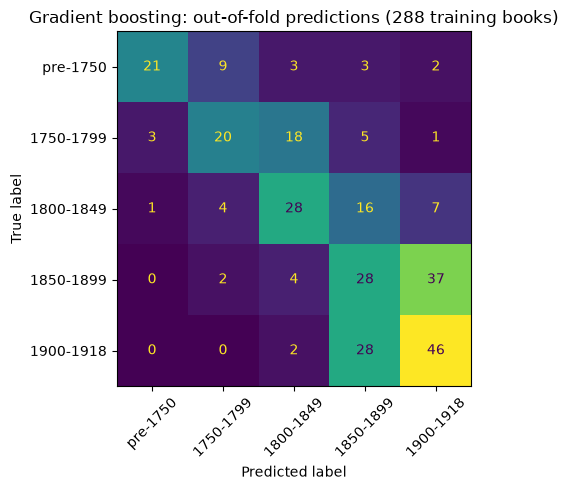

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(train["period"], train["pred"], labels=PERIODS,
                                        xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("Gradient boosting: out-of-fold predictions (288 training books)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "confusion_oof_boosting.png", dpi=150)
plt.show()

**Findings:** the out-of-fold predictions give macro-F1 0.515 and accuracy 0.497, in line with the cross-validation mean from notebook 03 (0.506). 145 of the 288 books are wrong, but 119 of them (82%) are only one period away; just 6 books are three or more periods away. The model usually gets the rough era right and the exact half-century wrong.

## Error slices with uncertainty

Each slice reports the number of books and authors, the accuracy (for a period slice this is the recall: the share of that period's books predicted correctly), and a **95% confidence interval** from a bootstrap.

The bootstrap resamples authors, not books, 1,000 times: books by the same author tend to be right or wrong together, so resampling single books would make the intervals look narrower than they really are.

Besides the five periods, books are also split by **distance from the nearest period boundary** (1750, 1800, 1850, 1900): a book from 1898 is likely to read much like one from 1902, so errors should be more common near a boundary.

In [5]:
rng = np.random.default_rng(config.RANDOM_STATE)

def group_bootstrap(df, stat, n=1000):
    """95% interval for stat(df), resampling authors (groups) with replacement."""
    rows_of = df.groupby("group").indices
    authors = list(rows_of)
    values = []
    for _ in range(n):
        pick = rng.choice(len(authors), size=len(authors), replace=True)
        rows = np.concatenate([rows_of[authors[i]] for i in pick])
        values.append(stat(df.iloc[rows]))
    return np.percentile(values, [2.5, 97.5])

def accuracy(d):
    return (d["period"] == d["pred"]).mean()

def slice_row(name, d):
    lo, hi = group_bootstrap(d, accuracy)
    errs = d[d["error_size"] > 0]
    return {"slice": name, "books": len(d), "authors": d["group"].nunique(),
            "accuracy": round(accuracy(d), 3), "95% CI": f"{lo:.2f}–{hi:.2f}",
            "errors in neighbouring period": f"{(errs['error_size'] == 1).mean():.0%}" if len(errs) else "–"}

BOUNDARIES = [1750, 1800, 1850, 1900]
train["years_from_boundary"] = train["publication_date"].apply(lambda yr: min(abs(yr - b) for b in BOUNDARIES))
near = train["years_from_boundary"] <= 10

rows = [slice_row("All training books", train)]
rows += [slice_row(p, train[train["period"] == p]) for p in PERIODS]
rows += [slice_row("Within 10 years of a boundary", train[near]),
         slice_row("More than 10 years from a boundary", train[~near])]
slices = pd.DataFrame(rows)
slices

,slice,books,authors,accuracy,95% CI,errors in neighbouring period
0,All training books,288,275,0.497,0.44–0.55,82%
1,pre-1750,38,35,0.553,0.38–0.72,53%
2,1750-1799,47,45,0.426,0.29–0.57,78%
3,1800-1849,56,54,0.500,0.38–0.64,71%
4,1850-1899,71,69,0.394,0.28–0.52,95%
5,1900-1918,76,73,0.605,0.50–0.72,93%
6,Within 10 years of a boundary,136,133,0.397,0.32–0.47,82%
7,More than 10 years from a boundary,152,147,0.586,0.50–0.66,83%


**Findings:**
- **1850–1899 is the hardest period:** only 39% of its books are predicted correctly (95% CI 0.28–0.52), and 95% of its errors are in a neighbouring period. 1900–1918 is the easiest (0.61, CI 0.50–0.72).
- **Books near a period boundary are much harder:** 0.40 (CI 0.32–0.47) within 10 years of a boundary against 0.59 (CI 0.50–0.66) further away; the intervals do not overlap. This is expected, because language changes gradually, but fixed period boundaries treat 1849 and 1851 as completely different.
- Caveats: the periods are not equally spread around the boundaries (1900–1918 is only 19 years wide, so most of its books are within 10 years of 1900), so the boundary and period slices overlap. With 38–76 books per period the intervals are wide, so small differences between periods (e.g. 0.43 vs 0.50) are not meaningful.

## The 1850–1899 / 1900–1918 confusion

These two periods are the largest and are next to each other. The books confused between them are listed below with their publication year, to see whether the mistakes cluster around 1900.

In [6]:
late = train[train["period"].isin(["1850-1899", "1900-1918"])]
mixed = late[late["pred"].isin(["1850-1899", "1900-1918"]) & (late["period"] != late["pred"])]
correct = late[late["period"] == late["pred"]]

print(f"{len(mixed)} of {len(late)} books from these two periods are predicted as the other one")
print(f"Median years from 1900: confused {mixed['publication_date'].sub(1900).abs().median():.0f}, "
      f"correct {correct['publication_date'].sub(1900).abs().median():.0f}")
mixed[["title", "publication_date", "period", "pred"]].sort_values("publication_date")

65 of 147 books from these two periods are predicted as the other one
Median years from 1900: confused 10, correct 11


,title,publication_date,period,pred
158,Off-Hand Sketches by T. S. Arthur,1851,1850-1899,1900-1918
174,The Lady's Country Companion by Jane Webb Loudon,1852,1850-1899,1900-1918
152,Address to the People of the United States tog...,1855,1850-1899,1900-1918
172,Aaron Trow by Anthony Trollope,1864,1850-1899,1900-1918
160,Feats on the Fiord by Harriet Martineau,1865,1850-1899,1900-1918
...,...,...,...,...
263,The Problem of Truth by H. Wildon Carr,1913,1900-1918,1850-1899
287,The Snakes of Europe by G. A. Boulenger,1913,1900-1918,1850-1899
273,Cornwall's Wonderland by Mabel Quiller-Couch,1914,1900-1918,1850-1899
267,Frank Forester by Herbert Strang,1915,1900-1918,1850-1899


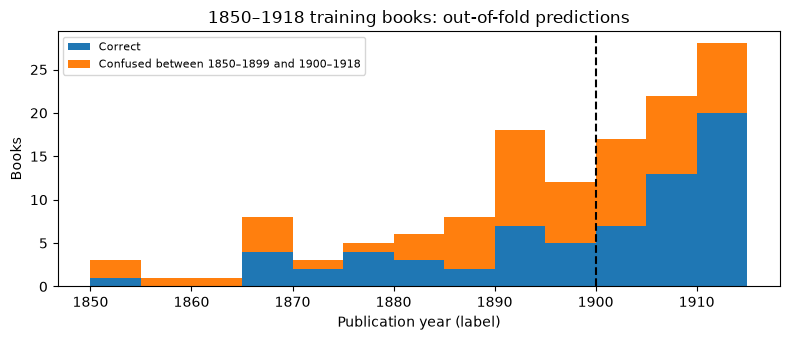

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = range(1850, 1920, 5)
ax.hist([correct["publication_date"], mixed["publication_date"]], bins=bins, stacked=True,
        label=["Correct", "Confused between 1850–1899 and 1900–1918"])
ax.axvline(1900, color="black", linestyle="--")
ax.set_xlabel("Publication year (label)")
ax.set_ylabel("Books")
ax.set_title("1850–1918 training books: out-of-fold predictions")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "confusion_1850_1900_by_year.png", dpi=150)
plt.show()

**Findings:** 65 of the 147 books from 1850–1918 (44%) are predicted as the other of these two periods. Unexpectedly, the confused books are **not** closer to 1900 than the correctly predicted ones (median 10 vs 11 years from 1900): books from the 1850s and 1860s are predicted as 1900–1918, and 1910s books as 1850–1899 (see the histogram). So for these two periods the mistakes are not mainly a boundary effect. The titles suggest the model is partly separating by **topic or genre** (e.g. a 1917 *Bayonet Training Manual* and a 1913 natural-history book are predicted as 1850–1899) rather than by date, which is a limitation of word-frequency features.

## Final test-set performance with uncertainty

The final model from notebook 03 (boosting trained on all 288 training books, fixed seed) is rebuilt and its test predictions are recomputed, so the model card can report a confidence interval. The macro-F1 must match notebook 03 (0.519). These numbers are **reported only**: nothing is tuned or chosen from them.

In [8]:
final_model = boosting_model().fit(train["excerpt"], train["period"])
test["pred"] = final_model.predict(test["excerpt"])
test["error_size"] = (test["period"].map(INDEX) - test["pred"].map(INDEX)).abs()

def macro_f1(d):
    return f1_score(d["period"], d["pred"], average="macro", labels=PERIODS, zero_division=0)

lo, hi = group_bootstrap(test, macro_f1)
print(f"Test macro-F1: {macro_f1(test):.3f} (95% CI {lo:.2f}–{hi:.2f}, resampling authors)")
lo, hi = group_bootstrap(test, accuracy)
print(f"Test accuracy: {accuracy(test):.3f} (95% CI {lo:.2f}–{hi:.2f})")

pd.DataFrame([slice_row(p, test[test["period"] == p]) for p in PERIODS])

Test macro-F1: 0.519 (95% CI 0.37–0.63, resampling authors)
Test accuracy: 0.507 (95% CI 0.39–0.62)


,slice,books,authors,accuracy,95% CI,errors in neighbouring period
0,pre-1750,10,6,0.700,0.33–0.90,33%
1,1750-1799,11,11,0.455,0.18–0.73,83%
2,1800-1849,14,14,0.357,0.14–0.64,67%
3,1850-1899,17,17,0.353,0.12–0.59,91%
4,1900-1918,19,19,0.684,0.47–0.89,100%


**Findings:** the rebuilt model reproduces notebook 03's test result exactly: **macro-F1 0.52 (95% CI 0.37–0.63)** and accuracy 0.51 (CI 0.39–0.62). The interval is wide because there are only 71 test books from 66 authors. The per-period test intervals are even wider (10–19 books each, e.g. 0.12–0.59 for 1850–1899), so the out-of-fold slices above, from 288 books, are the better evidence for where the model fails; the test results agree with them (1850–1899 and 1800–1849 weakest, 1900–1918 and pre-1750 strongest).

## Calibration: can the predicted probabilities be trusted?

Besides a period, the model gives a probability for each period. If it says "70% sure", it should be right about 70% of the time. This is checked on the out-of-fold probabilities: books are grouped by the model's confidence (its highest probability) and the share actually correct is compared with the average confidence. The **expected calibration error (ECE)** is the average gap, weighted by the number of books.

In [9]:
CLASSES = np.array(sorted(PERIODS))  # the order scikit-learn uses for predict_proba
proba = cross_val_predict(boosting_model(), train["excerpt"], train["period"],
                          groups=train["group"], cv=cv, method="predict_proba")
confidence = proba.max(axis=1)
pred_from_proba = CLASSES[proba.argmax(axis=1)]
print("Same predictions as above:", (pred_from_proba == train["pred"]).all())

cal = pd.DataFrame({"confidence": confidence, "correct": pred_from_proba == train["period"]})
cal["bin"] = pd.cut(cal["confidence"], [0, 0.4, 0.6, 0.8, 0.95, 1.0], include_lowest=True)
calib = cal.groupby("bin", observed=True).agg(books=("correct", "size"),
                                               mean_confidence=("confidence", "mean"),
                                               accuracy=("correct", "mean"))
ece = (calib["books"] * (calib["mean_confidence"] - calib["accuracy"]).abs()).sum() / len(cal)
print(f"Average confidence {confidence.mean():.2f}, accuracy {cal['correct'].mean():.2f}, ECE {ece:.3f}")
calib.round(3)

Same predictions as above: True
Average confidence 0.78, accuracy 0.50, ECE 0.281


,books,mean_confidence,accuracy
bin,,,
"(-0.001, 0.4]",8,0.360,0.375
"(0.4, 0.6]",52,0.525,0.385
"(0.6, 0.8]",78,0.703,0.423
"(0.8, 0.95]",86,0.882,0.535
"(0.95, 1.0]",64,0.980,0.641


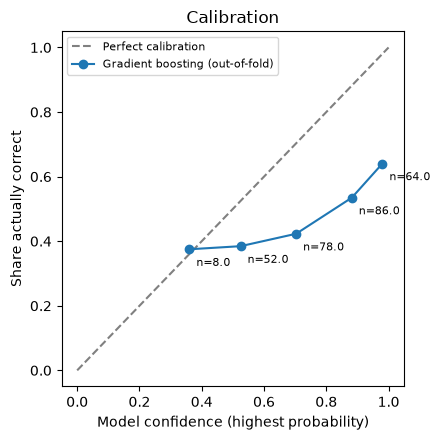

In [10]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
ax.plot(calib["mean_confidence"], calib["accuracy"], "o-", label="Gradient boosting (out-of-fold)")
for _, r in calib.iterrows():
    ax.annotate(f"n={r['books']}", (r["mean_confidence"], r["accuracy"]), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set_xlabel("Model confidence (highest probability)")
ax.set_ylabel("Share actually correct")
ax.set_title("Calibration")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "calibration_boosting.png", dpi=150)
plt.show()

**Findings:** the model is strongly **overconfident**. Its average confidence is 0.78 but only 50% of its predictions are correct (ECE 0.28). Accuracy does rise with confidence (0.39 at 0.4–0.6 up to 0.64 above 0.95), so the probabilities still rank books sensibly, but even when the model is more than 95% sure (64 books) it is wrong about a third of the time. Boosting with 400 rounds pushes its probabilities towards 0 and 1, which is a common cause of this.

**Consequence:** the predicted probabilities should not be shown to users as a measure of confidence. Recalibrating them (e.g. `CalibratedClassifierCV`, fitted within cross-validation) is a possible improvement but was not tested here.

## Global explanation: which words does the model rely on?

**Permutation importance** measures how much the score drops when one word's TF-IDF values are shuffled between books, breaking its link with the period. It is computed on held-out books: in each of the 5 folds, the model is trained on the other 4 folds and the words are shuffled in the validation fold (5 repeats each), then the drops are averaged over the folds.

Shuffling all 7,123 words would take too long, so in each fold only the 150 words the trained trees use most (`feature_importances_`, which comes from the training data only) are tested; a word not tested in a fold counts as 0 there. The last column shows the period in which each word is most frequent (average TF-IDF), to give its direction.

In [11]:
TOP_K, REPEATS = 150, 5
rng_perm = np.random.default_rng(config.RANDOM_STATE)
rows = []
for k, (tr, va) in enumerate(cv.split(train, train["period"], train["group"]), start=1):
    model = boosting_model().fit(train["excerpt"].iloc[tr], train["period"].iloc[tr])
    vec, clf = model[0], model[-1]
    words = vec.get_feature_names_out()
    X_va = vec.transform(train["excerpt"].iloc[va]).toarray()
    y_va = train["period"].iloc[va].to_numpy()
    base = f1_score(y_va, clf.predict(X_va), average="macro")
    for j in np.argsort(clf.feature_importances_)[::-1][:TOP_K]:
        drops = []
        for _ in range(REPEATS):
            X_p = X_va.copy()
            X_p[:, j] = rng_perm.permutation(X_p[:, j])
            drops.append(base - f1_score(y_va, clf.predict(X_p), average="macro"))
        rows.append({"fold": k, "word": words[j], "drop": np.mean(drops)})
    print(f"fold {k} done")

by_fold = pd.DataFrame(rows).pivot_table(index="word", columns="fold", values="drop", fill_value=0)
by_fold = by_fold.reindex(columns=range(1, 6), fill_value=0)

# direction: period where each word is most frequent (vectoriser of the final model, fitted on all training books)
vec_all = final_model[0]
X_all = vec_all.transform(train["excerpt"])
vocab = {w: i for i, w in enumerate(vec_all.get_feature_names_out())}
mean_by_period = pd.DataFrame({p: np.asarray(X_all[(train["period"] == p).to_numpy()].mean(axis=0)).ravel() for p in PERIODS})

importance = pd.DataFrame({
    "mean_drop_macro_f1": by_fold.mean(axis=1),
    "std_over_folds": by_fold.std(axis=1, ddof=0),
    "folds_with_drop": (by_fold > 0).sum(axis=1),
})
importance["most_frequent_in"] = [mean_by_period.iloc[vocab[w]].idxmax() for w in importance.index]
importance = importance.sort_values("mean_drop_macro_f1", ascending=False)
print("Words with a positive average drop:", (importance["mean_drop_macro_f1"] > 0).sum())
importance.head(15).round(4)

fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done
Words with a positive average drop: 131


,mean_drop_macro_f1,std_over_folds,folds_with_drop,most_frequent_in
word,,,,
persons,0.0098,0.0197,1,pre-1750
attended,0.0089,0.0178,1,1800-1849
took,0.0086,0.0172,1,1850-1899
proper,0.0084,0.0108,2,1750-1799
feel,0.0079,0.0174,1,1850-1899
across,0.0074,0.0149,1,1900-1918
shew,0.0068,0.0087,2,1750-1799
totally,0.0067,0.0134,1,1750-1799
length,0.0063,0.0127,1,1750-1799


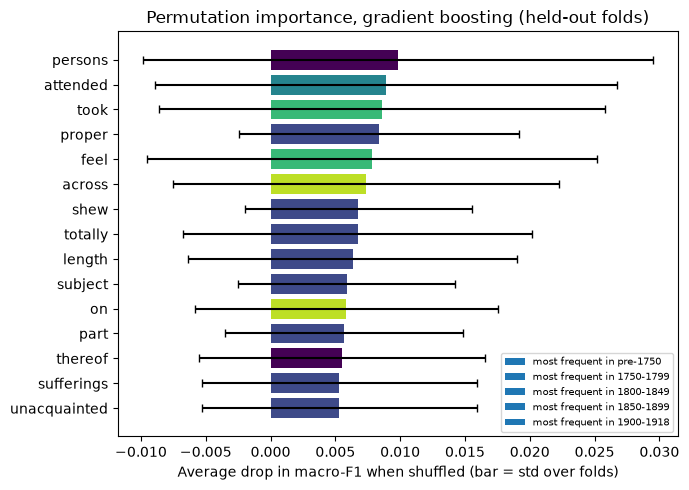

In [12]:
top = importance.head(15).iloc[::-1]
colours = dict(zip(PERIODS, plt.cm.viridis(np.linspace(0, 0.9, len(PERIODS)))))
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["mean_drop_macro_f1"], xerr=top["std_over_folds"],
        color=[colours[p] for p in top["most_frequent_in"]], capsize=3)
for p in PERIODS:
    ax.barh([], [], color=colours[p], label=f"most frequent in {p}")
ax.set_xlabel("Average drop in macro-F1 when shuffled (bar = std over folds)")
ax.set_title("Permutation importance, gradient boosting (held-out folds)")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "permutation_importance_boosting.png", dpi=150)
plt.show()

**Findings:**
- **No single word matters much.** The biggest average drop from shuffling one word is about 0.01 macro-F1, most of the top words reduced the score in only 1–2 of the 5 folds, and their standard deviations are larger than their means. The model spreads its reliance over many words, so removing any one of them changes little (see the correlation warning below).
- **Some patterns are still visible.** Words most frequent in the older periods include an old spelling (*shew* for "show") and formal vocabulary (*thereof*, *unacquainted*, *sufferings*, *proper*, *subject*, *persons*), while those most frequent in the later periods are plainer (*across*, *took*, *feel*, *on*). This fits the style features in notebook 05 (shorter, plainer sentences over time), but with such small, noisy drops it is suggestive rather than strong evidence.
- No obvious leakage words (years, publisher names, modern editorial terms) appear among the 15 top words.

## Local explanation: why did the model date one book wrongly?

One test book from 1850–1899 that the final model predicted as 1900–1918 (the most common confusion) is explained by **leaving out one word at a time**: each word in the book is set to zero in turn, and the change in the predicted probabilities is recorded. A word whose removal lowers the probability of the predicted period was pushing the model *towards* that period. The same is done for the true period. The first such book by id is used, so the choice is not cherry-picked.

In [13]:
wrong = test[(test["period"] == "1850-1899") & (test["pred"] == "1900-1918")]
book = (wrong if len(wrong) else test[test["error_size"] > 0]).sort_values("id").iloc[0]

vec, clf = final_model[0], final_model[-1]
classes = list(clf.classes_)
x = vec.transform([book["excerpt"]])
p = clf.predict_proba(x)[0]
print(f"{book['title']} ({book['publication_date']}): true {book['period']}, predicted {book['pred']}")
print("Predicted probabilities:", {c: round(v, 2) for c, v in zip(classes, p)})

present = x.nonzero()[1]
X_rep = np.repeat(x.toarray(), len(present), axis=0)
X_rep[np.arange(len(present)), present] = 0  # each row: the book with one word removed
p_rep = clf.predict_proba(X_rep)
i_pred, i_true = classes.index(book["pred"]), classes.index(book["period"])
effects = pd.DataFrame({
    "word": vec.get_feature_names_out()[present],
    "towards_predicted": p[i_pred] - p_rep[:, i_pred],
    "towards_true": p[i_true] - p_rep[:, i_true],
})
print(f"{len(present)} vocabulary words in this excerpt")
pd.concat([effects.nlargest(10, "towards_predicted").reset_index(drop=True).add_suffix(" (pred)"),
           effects.nlargest(10, "towards_true").reset_index(drop=True).add_suffix(" (true)")], axis=1).round(3)

Demos by George Gissing (1886): true 1850-1899, predicted 1900-1918
Predicted probabilities: {'1750-1799': np.float64(0.0), '1800-1849': np.float64(0.01), '1850-1899': np.float64(0.03), '1900-1918': np.float64(0.96), 'pre-1750': np.float64(0.0)}
1154 vocabulary words in this excerpt


,word (pred),towards_predicted (pred),towards_true (pred),word (true),towards_predicted (true),towards_true (true)
0,approval,0.040,-0.030,words,-0.011,0.011
1,wasn,0.028,-0.021,comrade,-0.009,0.009
2,little,0.027,-0.027,voice,-0.009,0.009
3,started,0.027,-0.020,shall,-0.010,0.008
4,doesn,0.023,-0.017,as,-0.007,0.007
5,slowly,0.022,-0.017,because,-0.008,0.007
6,later,0.021,-0.014,grew,-0.007,0.007
7,chin,0.021,-0.016,richard,-0.007,0.007
8,working,0.016,-0.012,standing,-0.007,0.007
9,newspaper,0.016,-0.012,having,-0.009,0.006


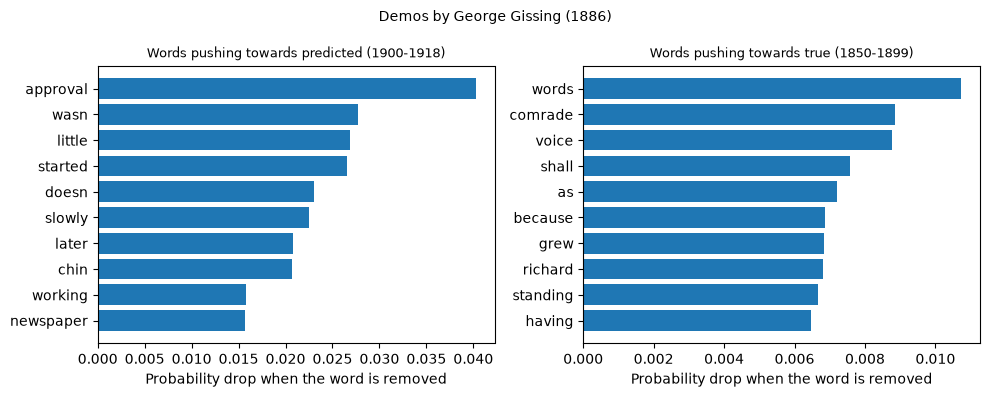

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, label in [(axes[0], "towards_predicted", f"towards predicted ({book['pred']})"),
                       (axes[1], "towards_true", f"towards true ({book['period']})")]:
    t = effects.nlargest(10, col).iloc[::-1]
    ax.barh(t["word"], t[col])
    ax.set_xlabel("Probability drop when the word is removed")
    ax.set_title(f"Words pushing {label}", fontsize=9)
plt.suptitle(f"{book['title']} ({book['publication_date']})", fontsize=10)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "local_explanation_example.png", dpi=150)
plt.show()

**Findings:** the book is George Gissing's *Demos* (1886), a realist novel about working-class life and socialism. The model puts it in 1900–1918 with **96%** probability (and only 3% for its true period), a clear example of the overconfidence found above.
- Words pushing it **towards 1900–1918** include contractions from dialogue (*wasn*, *doesn*) and everyday modern-sounding words (*newspaper*, *working*, *started*, *later*, *slowly*). Gissing's realistic everyday speech seems to read as "modern" to the model.
- Words pulling it **back towards 1850–1899** include *comrade*, *shall* and *voice*, but also *richard*, a character's name (Richard Mutimer), so names still have some influence despite `min_df=10`.
- No single word moves the probability by more than 0.04, so the wrong prediction comes from many small pushes together, not one decisive word.

This matches the 1850–1899 / 1900–1918 finding above: the model reacts to style and subject matter (informal dialogue, working life) that it associates with later books, rather than to anything that fixes the date.

### Limits of these explanation methods

- **Not causal.** Both methods show what the *model* relies on, not what makes a text belong to a period. A word can be important because it is linked to topics or genres that happen to be common in one period in this sample.
- **Correlated words share credit.** Permutation importance shuffles one word at a time; words that carry the same information (e.g. *thee* and *thou*) can each look unimportant because the other still carries the signal, so the list understates groups of related words.
- **Only 150 words per fold were tested**, chosen by the trees' own importance scores, so a word outside that list is reported as 0 even if it matters a little.
- **Small, noisy drops.** Each validation fold has only ~58 books, so shuffling one word changes few predictions; the standard deviations over folds are large.
- **Leave-one-word-out** looks at each word on its own and ignores interactions; setting a TF-IDF value to zero is also not the same as rewriting the text without that word. It explains one prediction of one model and can change if the model is retrained.

In [15]:
cols = ["id", "title", "publication_date", "period", "group", "pred", "error_size"]
train[cols].to_csv(config.ROOT / "reports" / "oof_predictions_boosting.csv", index=False)
slices.to_csv(config.ROOT / "reports" / "error_slices.csv", index=False)
importance.to_csv(config.ROOT / "reports" / "permutation_importance_boosting.csv")
calib.to_csv(config.ROOT / "reports" / "calibration_boosting.csv")
print("Saved out-of-fold predictions, error slices, permutation importance and calibration table")

Saved out-of-fold predictions, error slices, permutation importance and calibration table
